# Detección de enfermedades en hojas de cultivos mediante Redes Neuronales Convolucionales

**Evaluación Parcial N° 2 — Implementación y optimización de Redes Convolucionales**
**Asignatura:** DLY0100 Deep Learning — DUOC UC
**Estudiante:** Verónica San Martín
**Fecha:** noviembre 2026

## Índice

1. Introducción
2. Herramientas utilizadas y justificación
3. Carga y exploración de datos
4. Preprocesamiento
5. Modelo 1: CNN base
6. Modelo 2: CNN mejorada (regularización)
7. Modelo 3: Red residual (ResNet)
8. Ajuste de hiperparámetros
9. Comparación de arquitecturas
10. Evaluación del modelo final en el conjunto de test
11. Justificación del modelo final
12. Conclusiones
13. Referencias

## 1. Introducción

### 1.1 Contexto
Las enfermedades de las plantas son una de las principales causas de pérdida de rendimiento en la agricultura. Su detección suele depender de la inspección visual de un especialista, lo que es lento, costoso y difícil de escalar en grandes extensiones de cultivo. Detectar una enfermedad en etapa temprana permite aplicar el tratamiento a tiempo y reducir pérdidas.

La visión artificial ofrece una alternativa: a partir de una fotografía de la hoja, un modelo puede identificar si la planta está sana o qué enfermedad presenta. Las **Redes Neuronales Convolucionales (CNN)** son la arquitectura de referencia para este tipo de problemas, porque aprenden patrones locales (bordes, manchas, texturas, cambios de color) y los combinan en representaciones de mayor nivel, sin necesidad de definir manualmente las características.

### 1.2 Problema
Se busca clasificar automáticamente imágenes de hojas de **pimentón, papa y tomate** en **15 clases**: 3 corresponden a hojas sanas y 12 a distintas enfermedades (bacterianas, fúngicas, virales y por plagas). Es un problema de **clasificación multiclase de imágenes**.

### 1.3 Objetivos

**Objetivo general:** Implementar, optimizar y evaluar un modelo CNN capaz de clasificar enfermedades en hojas de cultivos a partir de imágenes.

**Objetivos específicos:**
- Explorar y preprocesar el dataset PlantVillage, identificando sus características y limitaciones (por ejemplo, el desbalance de clases).
- Diseñar y entrenar distintas arquitecturas: una CNN base, una CNN con técnicas de regularización y una red residual (ResNet).
- Ajustar hiperparámetros (tasa de aprendizaje, tamaño de batch, dropout) y analizar su impacto mediante métricas y gráficos.
- Evaluar los modelos con accuracy, loss, precision, recall y F1-score, y justificar técnicamente la elección del modelo final.

### 1.4 Dataset
Se utiliza un subconjunto del dataset público **PlantVillage** (Hughes & Salathé, 2015), con **20.638 imágenes RGB de 256×256 píxeles** distribuidas en 15 clases. Las imágenes fueron tomadas en condiciones controladas (una hoja por imagen, fondo uniforme), lo que facilita el aprendizaje, pero es una limitación que se discute en las conclusiones.

In [ ]:
# El zip lo subí directo al panel de archivos de Colab, así que queda en /content/
# Lo descomprimimos en /content/data
!unzip -q /content/PlantVillage_limpio.zip -d /content/data

# Verificación rápida: deberían salir 15 carpetas (una por clase)
!ls /content/data/PlantVillage | wc -l

15


Celda 3.1 – Configuración del entorno
El archivo PlantVillage_limpio.zip fue depurado previamente: el original contenía una copia duplicada de todas las imágenes en una subcarpeta, archivos de sistema de macOS (__MACOSX) y un archivo que no era imagen. Si no se elimina, el duplicado haría que Keras detecte una clase 16 inexistente y que las mismas imágenes aparezcan en entrenamiento y en test, inflando artificialmente las métricas.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Semilla fija: resultados reproducibles, para comparar modelos de forma justa
SEED = 42
keras.utils.set_random_seed(SEED)

DATA_DIR = '/content/data/PlantVillage'
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 3.2 Distribución de imágenes por clase
Se cuenta cuántas imágenes tiene cada clase para detectar posibles desbalances.

                                      clase  imagenes
                           Potato___healthy       152
                Tomato__Tomato_mosaic_virus       373
                           Tomato_Leaf_Mold       952
              Pepper__bell___Bacterial_spot       997
                        Tomato_Early_blight      1000
                      Potato___Early_blight      1000
                       Potato___Late_blight      1000
                        Tomato__Target_Spot      1404
                     Pepper__bell___healthy      1478
                             Tomato_healthy      1591
Tomato_Spider_mites_Two_spotted_spider_mite      1676
                  Tomato_Septoria_leaf_spot      1771
                         Tomato_Late_blight      1909
                      Tomato_Bacterial_spot      2127
      Tomato__Tomato_YellowLeaf__Curl_Virus      3208

Total imágenes: 20638
Desbalance (clase mayor / clase menor): 21.1


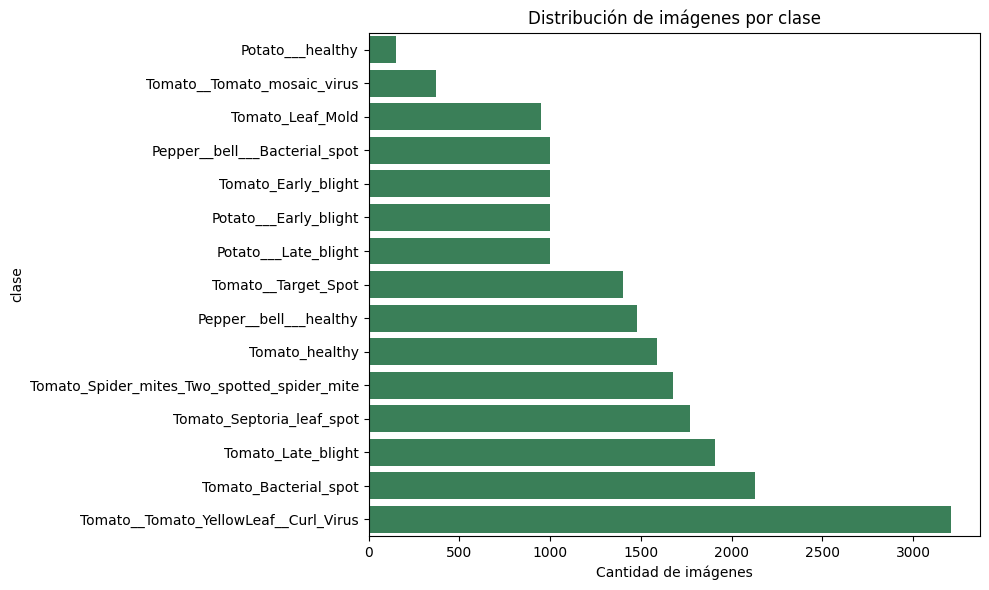

In [ ]:
# Cada carpeta es una clase; contamos sus imágenes
conteo = {c: len(os.listdir(os.path.join(DATA_DIR, c)))
          for c in sorted(os.listdir(DATA_DIR))}

df = pd.DataFrame(list(conteo.items()), columns=['clase', 'imagenes']).sort_values('imagenes')
print(df.to_string(index=False))
print("\nTotal imágenes:", df['imagenes'].sum())
print("Desbalance (clase mayor / clase menor):", round(df['imagenes'].max() / df['imagenes'].min(), 1))

plt.figure(figsize=(10, 6))
sns.barplot(data=df, y='clase', x='imagenes', color='seagreen')
plt.title('Distribución de imágenes por clase')
plt.xlabel('Cantidad de imágenes')
plt.tight_layout()
plt.show()

A considerar:
Dos clases quedan muy por debajo del resto: Potato healthy, con unas 150 imágenes, y Tomato mosaic virus, con unas 370. Esas dos son las que más riesgo tienen de que el modelo las clasifique mal, porque tiene pocos ejemplos para aprenderlas.
Hay una clase que domina: Tomato YellowLeaf Curl Virus, con unas 3.200, cerca del 16% de todo el dataset.
El tomate pesa mucho más que el resto: son 10 de las 15 clases. El modelo va a ver muchas más hojas de tomate que de papa o pimentón.
Varias clases tienen exactamente 1.000 imágenes. Probablemente el dataset original se recortó en esas clases. No es un problema, pero muestra que el desbalance viene de cómo se armó el dataset, no de la naturaleza.

### 3.3 Visualización de ejemplos por clase

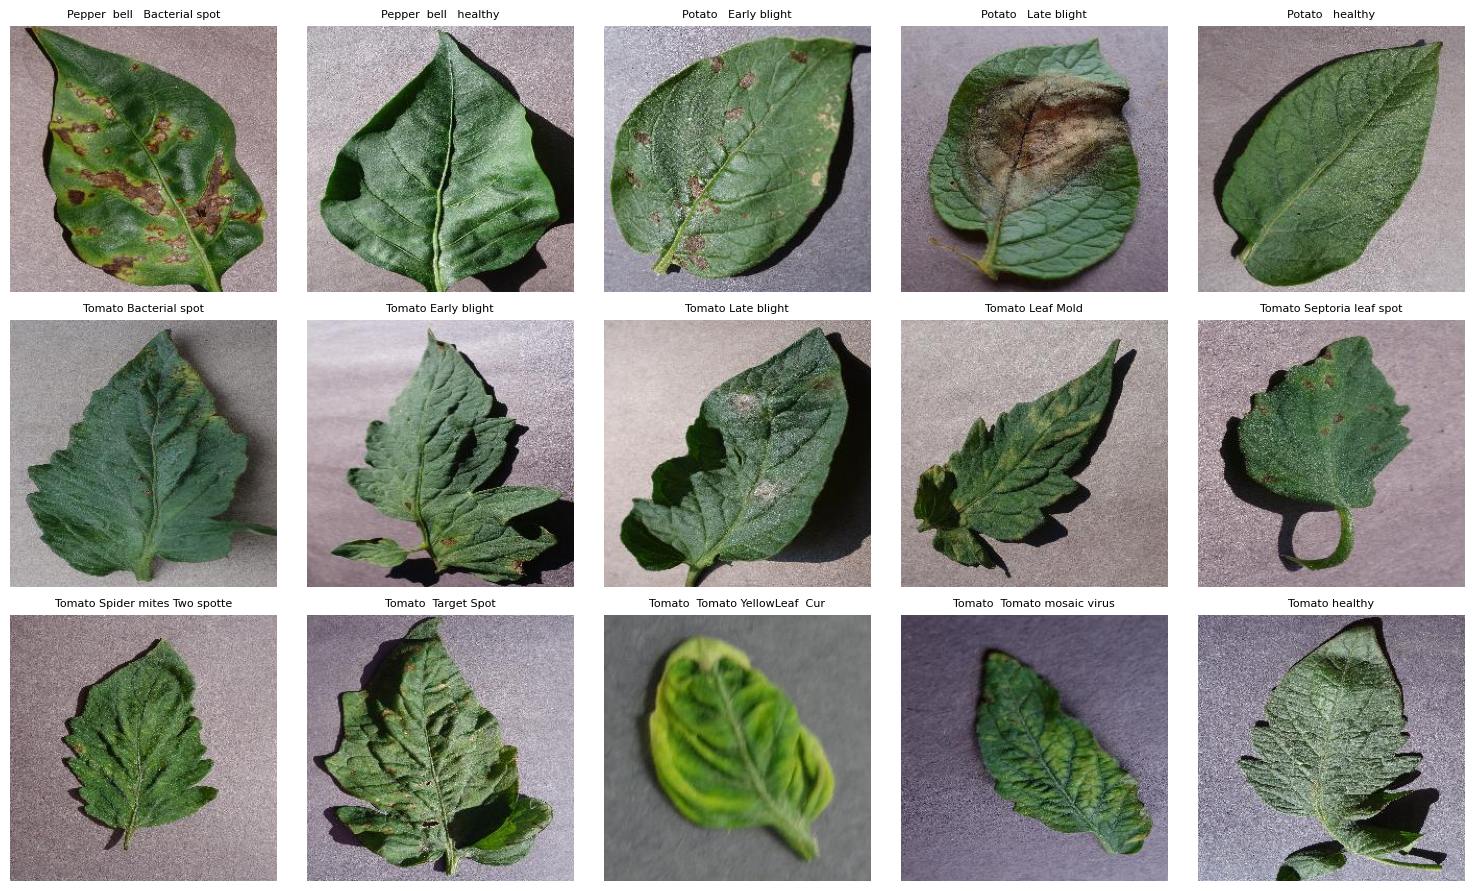

Forma de una imagen (alto, ancho, canales): (256, 256, 3)


In [ ]:
plt.figure(figsize=(15, 9))
for i, clase in enumerate(sorted(conteo)):
    archivo = os.listdir(os.path.join(DATA_DIR, clase))[0]
    img = plt.imread(os.path.join(DATA_DIR, clase, archivo))
    plt.subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(clase.replace('_', ' ')[:30], fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

print("Forma de una imagen (alto, ancho, canales):", img.shape)

### 3.4 Hallazgos del análisis exploratorio
Tamaño y formato: 20.638 imágenes RGB de 256×256 píxeles (3 canales), distribuidas en 15 clases de tres especies: pimentón, papa y tomate.
Desbalance fuerte: la clase más grande (Tomato YellowLeaf Curl Virus, 3.209 imágenes) tiene 21 veces más imágenes que la más pequeña (Potato healthy, 152). Tomato mosaic virus (~370) también queda muy por debajo del resto. Además, 10 de las 15 clases son de tomate, por lo que el modelo verá muchas más hojas de tomate que de papa o pimentón.
Implicancia para la evaluación: el accuracy no basta. Mide aciertos sobre el total de imágenes, por lo que lo dominan las clases grandes. Potato healthy es solo el 0,7% del dataset: un modelo podría tener 98% de accuracy y no reconocer nunca una papa sana. Por eso se evalúa también precision, recall y F1 por clase (con promedio macro) y la matriz de confusión.
Condiciones de captura controladas: todas las fotos tienen una sola hoja sobre fondo gris uniforme. Esto facilita el aprendizaje, pero limita la aplicación en terreno, donde hay tierra, sombras y varias hojas juntas.
Clases visualmente parecidas: algunas enfermedades producen síntomas similares (por ejemplo, manchas oscuras pequeñas en Bacterial spot y Septoria leaf spot, o lesiones marrones en Early blight y Late blight). Se anticipa que estas serán las principales fuentes de error.
## 4. Preprocesamiento
### 4.1 División en entrenamiento, validación y test

In [ ]:
from sklearn.model_selection import train_test_split

CLASES = sorted(os.listdir(DATA_DIR))
rutas, etiquetas = [], []
for i, clase in enumerate(CLASES):
    for archivo in os.listdir(os.path.join(DATA_DIR, clase)):
        rutas.append(os.path.join(DATA_DIR, clase, archivo))
        etiquetas.append(i)
rutas = np.array(rutas)
etiquetas = np.array(etiquetas)

# 1) División 80/20: entrenamiento vs test (como en clase)
#    El test se separa PRIMERO y no se vuelve a tocar hasta la evaluación final
X_trval, X_test, y_trval, y_test = train_test_split(
    rutas, etiquetas, test_size=0.20, stratify=etiquetas, random_state=SEED)

# 2) Del 80% de entrenamiento, separamos un 20% para validación
#    (equivale a validation_split=0.2, pero estratificado)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.20, stratify=y_trval, random_state=SEED)

print(f"Entrenamiento: {len(X_train)} | Validación: {len(X_val)} | Test: {len(X_test)}")

idx = CLASES.index('Potato___healthy')
print("Potato healthy ->",
      "train:", (y_train == idx).sum(),
      "| val:", (y_val == idx).sum(),
      "| test:", (y_test == idx).sum())

Entrenamiento: 13208 | Validación: 3302 | Test: 4128
Potato healthy -> train: 98 | val: 24 | test: 30


Se utiliza una división 80/20 entre entrenamiento y test. Del 80% de entrenamiento se reserva a su vez un 20% para validación (equivalente a validation_split=0.2). El resultado es:

Conjunto	       % del total	Imágenes	Potato healthy
Entrenamiento	  64%	            13.208	 98
Validación	    16%	             3.302	 24
Test	          20%	             4.128	 30
Se van a comparar varias arquitecturas y ajustar hiperparámetros. Si esas decisiones se tomaran mirando el test, el resultado final quedaría sesgado a favor (fuga de datos) y dejaría de representar el desempeño con imágenes nuevas. Las decisiones se toman con validación; el test se usa una sola vez, al final, con el modelo elegido.
Por qué estratificar (stratify): con solo 152 imágenes de Potato healthy, una división al azar podría dejar muy pocas en algún conjunto. La estratificación mantiene la misma proporción de cada clase en los tres conjuntos.
Reproducibilidad: se fija random_state=SEED (42), por lo que la división es siempre la misma y los modelos se comparan sobre los mismos datos.

### 4.2 Redimensionamiento y normalización

In [ ]:
IMG_SIZE = 128   # reducimos de 256 a 128: 4 veces menos cálculo
BATCH = 32       # imágenes que el modelo procesa antes de actualizar sus pesos
AUTOTUNE = tf.data.AUTOTUNE

def cargar_imagen(ruta, etiqueta):
    img = tf.io.read_file(ruta)                                    # lee el archivo
    img = tf.io.decode_image(img, channels=3, expand_animations=False)  # lo convierte en matriz RGB
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))               # 256x256 -> 128x128
    return img, etiqueta

def crear_dataset(X, y, mezclar):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if mezclar:
        # Solo se mezcla el entrenamiento, para que el modelo no vea las clases en orden
        ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.map(cargar_imagen, num_parallel_calls=AUTOTUNE)  # carga en paralelo
    ds = ds.batch(BATCH).prefetch(AUTOTUNE)  # prepara el siguiente lote mientras la GPU trabaja
    return ds

train_ds = crear_dataset(X_train, y_train, mezclar=True)
val_ds   = crear_dataset(X_val,   y_val,   mezclar=False)
test_ds  = crear_dataset(X_test,  y_test,  mezclar=False)

# Verificación: forma de un lote
imgs, labs = next(iter(train_ds))
print("Forma del lote:", imgs.shape)
print("Rango de píxeles:", float(tf.reduce_min(imgs)), "a", float(tf.reduce_max(imgs)))
print("Primeras etiquetas:", labs[:10].numpy())

Forma del lote: (32, 128, 128, 3)
Rango de píxeles: 0.0 a 255.0
Primeras etiquetas: [ 9  8 10  5  1  1  9  2 11  7]


Las imágenes se reducen de 256×256 a 128×128. La cantidad de parámetros de una capa convolucional no depende del tamaño de la imagen (el filtro es el mismo y se desliza por toda la imagen), pero el cálculo se reduce 4 veces (la mitad de alto × la mitad de ancho). A 128×128 las lesiones de las hojas siguen siendo visibles.
Las imágenes se cargan en lotes de 32 con tf.data: se leen en paralelo y se prepara el siguiente lote mientras la GPU entrena (prefetch). Solo se mezcla (shuffle) el conjunto de entrenamiento, para que el modelo no vea las clases en orden.
Forma de cada lote: (32, 128, 128, 3) = (tamaño del lote, alto, ancho, canales RGB).
La normalización de los píxeles (de 0–255 a 0–1) se hace dentro del modelo con una capa Rescaling(1/255), para que el modelo reciba siempre los datos en la misma escala, también al predecir imágenes nuevas.

5. Modelo 1: CNN base

Es la línea base: una CNN simple, sin regularización, para tener un punto de comparación. Lo esperable es que aprenda bien, pero que sobreajuste. Eso justifica el Modelo 2.

Celda 5.1: arquitectura

In [ ]:
NUM_CLASES = len(CLASES)  # 15

def crear_cnn_base():
    modelo = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Rescaling(1./255),              # normaliza píxeles de 0-255 a 0-1

        # Bloque 1: 32 filtros detectan rasgos simples (bordes, colores)
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),           # 128 -> 64

        # Bloque 2: 64 filtros combinan rasgos (manchas, texturas)
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),           # 64 -> 32

        # Bloque 3: 128 filtros detectan patrones más complejos
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),           # 32 -> 16

        layers.Flatten(),                      # 16x16x128 -> vector de 32.768 valores
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASES, activation='softmax')  # una probabilidad por clase
    ], name='CNN_base')
    return modelo

modelo_base = crear_cnn_base()
modelo_base.summary()

Model: "CNN_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,615 (16.36 MB)

 Trainable params: 4,289,615 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

iltros crecientes (32 → 64 → 128): los primeros detectan rasgos simples (bordes, colores) y los siguientes los combinan en patrones más complejos (manchas, texturas). Mientras la imagen se achica con el pooling, se hace más profunda en canales.
Cálculo de parámetros: (alto × ancho × canales de entrada + 1) × filtros. Primera capa: (3×3×3 + 1) × 32 = 896. Segunda: (3×3×32 + 1) × 64 = 18.496, porque sus filtros reciben los 32 mapas de la capa anterior.
padding='same': mantiene el tamaño de la imagen tras cada convolución, de modo que solo el pooling la reduce a la mitad.
Hallazgo clave: el 98% de los parámetros (4.194.432) está en la primera capa densa, por conectar los 32.768 valores del Flatten con 128 neuronas. Las capas convolucionales, que son las que "ven" las enfermedades, son apenas el 2%. Es el mismo problema que la guía 2.3.1 documenta para VGG (124 de sus 144 millones de parámetros están en las capas densas finales), y anticipa riesgo de sobreajuste.

Celda 5.2: entrenamiento

In [ ]:
modelo_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',   # etiquetas como enteros 0..14
    metrics=['accuracy']
)

# EarlyStopping: si val_loss no mejora en 4 épocas, se detiene
# y recupera los pesos de la mejor época (evita seguir sobreajustando)
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=4, restore_best_weights=True)

hist_base = modelo_base.fit(
    train_ds,
    validation_data=val_ds,     # se evalúa con VALIDACIÓN, nunca con test
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.6465 - loss: 1.0896 - val_accuracy: 0.8047 - val_loss: 0.5729
Epoch 2/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8424 - loss: 0.4777 - val_accuracy: 0.8310 - val_loss: 0.5064
Epoch 3/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9044 - loss: 0.2863 - val_accuracy: 0.9040 - val_loss: 0.2818
Epoch 4/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9353 - loss: 0.1933 - val_accuracy: 0.9116 - val_loss: 0.2709
Epoch 5/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9553 - loss: 0.1258 - val_accuracy: 0.8931 - val_loss: 0.3398
Epoch 6/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9700 - loss: 0.0892 - val_accuracy: 0.9064 - val_loss: 0.3095
Epoch 7/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9762 - loss: 0.0707 - val_accuracy: 0.8873 - val_loss: 0.4130
Epoch 8/20
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9811 - loss: 0.0612 - val_accuracy: 

Optimizador Adam con learning rate 0,001.
Pérdida sparse_categorical_crossentropy (etiquetas como enteros 0–14).
Hasta 20 épocas, batch 32.
EarlyStopping sobre val_loss con paciencia 4 y restore_best_weights=True: si la pérdida de validación no mejora en 4 épocas, se detiene y recupera los pesos de la mejor época.
Sin regularización, sin data augmentation y sin pesos por clase: es la línea base de comparación.

Celda 5.3: curvas y registro de resultado

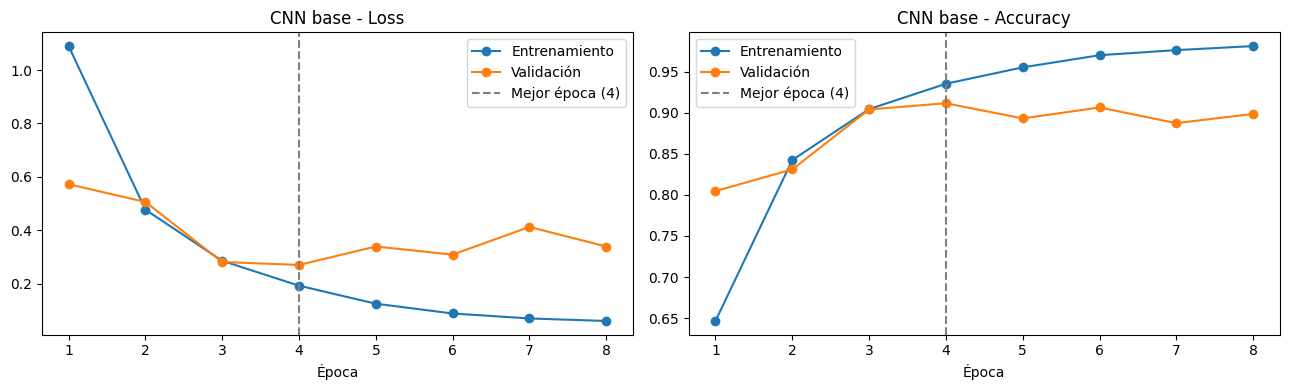

In [ ]:
def graficar_historia(hist, titulo):
    h = hist.history
    epocas = range(1, len(h['loss']) + 1)          # épocas numeradas desde 1
    mejor = int(np.argmin(h['val_loss'])) + 1      # época con menor val_loss
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for i, (m, nombre) in enumerate([('loss', 'Loss'), ('accuracy', 'Accuracy')]):
        ax[i].plot(epocas, h[m], marker='o', label='Entrenamiento')
        ax[i].plot(epocas, h['val_' + m], marker='o', label='Validación')
        ax[i].axvline(mejor, color='gray', linestyle='--', label=f'Mejor época ({mejor})')
        ax[i].set_title(f'{titulo} - {nombre}')
        ax[i].set_xlabel('Época'); ax[i].set_xticks(list(epocas)); ax[i].legend()
    plt.tight_layout(); plt.show()

graficar_historia(hist_base, 'CNN base')

# Guardamos las métricas para la tabla comparativa final
resultados = {}
mejor = int(np.argmin(hist_base.history['val_loss']))
resultados['CNN base'] = {
    'parametros': modelo_base.count_params(),
    'epocas': len(hist_base.history['loss']),
    'mejor_epoca': mejor + 1,
    'train_acc': hist_base.history['accuracy'][mejor],
    'val_acc': hist_base.history['val_accuracy'][mejor],
    'val_loss': hist_base.history['val_loss'][mejor],
}
pd.DataFrame(resultados).T
def graficar_historia(hist, titulo):
    h = hist.history
    epocas = range(1, len(h['loss']) + 1)          # épocas numeradas desde 1
    mejor = int(np.argmin(h['val_loss'])) + 1      # época con menor val_loss
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for i, (m, nombre) in enumerate([('loss', 'Loss'), ('accuracy', 'Accuracy')]):
        ax[i].plot(epocas, h[m], marker='o', label='Entrenamiento')
        ax[i].plot(epocas, h['val_' + m], marker='o', label='Validación')
        ax[i].axvline(mejor, color='gray', linestyle='--', label=f'Mejor época ({mejor})')
        ax[i].set_title(f'{titulo} - {nombre}')
        ax[i].set_xlabel('Época'); ax[i].set_xticks(list(epocas)); ax[i].legend()
    plt.tight_layout(); plt.show()

Mejor época: 4, con 93,5% de accuracy en entrenamiento y 91,2% en validación (val_loss 0,271).
Hasta la época 3–4, entrenamiento y validación mejoran juntos. Desde la época 5, el accuracy de entrenamiento sigue subiendo hasta 98,1%, mientras la validación se estanca en torno a 89–90% y el val_loss sube (de 0,27 a 0,41). Es sobreajuste: el modelo empieza a memorizar las imágenes de entrenamiento.
El EarlyStopping detuvo el entrenamiento en la época 8 y recuperó los pesos de la época 4.
Este comportamiento es coherente con la concentración del 98% de los parámetros en una sola capa densa, que le da al modelo capacidad de sobra para memorizar. Esto motiva el Modelo 2.

6. Modelo 2: CNN mejorada (regularización)

Celda 6.1: pesos por clase y arquitectura

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Peso por clase: las clases con menos imágenes reciben más peso en el loss
pesos = compute_class_weight('balanced', classes=np.arange(NUM_CLASES), y=y_train)
class_weight = dict(enumerate(pesos))
print(pd.DataFrame({'clase': CLASES, 'peso': np.round(pesos, 2)}).sort_values('peso', ascending=False).head(5))

# Data augmentation: solo actúa durante el entrenamiento, no en validación ni test
augmentation = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),    # rota hasta ±36°
    layers.RandomZoom(0.1),        # acerca o aleja hasta un 10%
], name='augmentation')

def bloque_conv(x, filtros):
    # Conv -> BatchNorm -> ReLU -> MaxPool
    x = layers.Conv2D(filtros, (3, 3), padding='same', use_bias=False)(x)  # el sesgo lo aporta BatchNorm
    x = layers.BatchNormalization(momentum=0.9)(x)  # promedio móvil más reactivo
    x = layers.Activation('relu')(x)
    return layers.MaxPooling2D((2, 2))(x)

def crear_cnn_mejorada(dropout=0.5):
    entrada = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation(entrada)
    x = layers.Rescaling(1./255)(x)
    # Mismos filtros que el modelo base (32, 64, 128) para comparar de forma justa
    x = bloque_conv(x, 32)
    x = bloque_conv(x, 64)
    x = bloque_conv(x, 128)
    x = layers.GlobalAveragePooling2D()(x)   # 16x16x128 -> 128 valores
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    salida = layers.Dense(NUM_CLASES, activation='softmax')(x)
    return keras.Model(entrada, salida, name='CNN_mejorada')

modelo_mejorado = crear_cnn_mejorada()
modelo_mejorado.summary()
print("Momentum BatchNorm:", [l.momentum for l in modelo_mejorado.layers if isinstance(l, layers.BatchNormalization)])

                          clase  peso
4              Potato___healthy  8.99
13  Tomato__Tomato_mosaic_virus  3.70
8              Tomato_Leaf_Mold  1.44
6           Tomato_Early_blight  1.38
3          Potato___Late_blight  1.38


Model: "CNN_mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,367 (438.93 KB)

 Trainable params: 111,919 (437.18 KB)

 Non-trainable params: 448 (1.75 KB)

Momentum BatchNorm: [0.9, 0.9, 0.9]


Mantiene los mismos tres bloques convolucionales (32, 64 y 128 filtros) para que la comparación con el modelo base sea justa, y agrega:
  

GlobalAveragePooling2D en vez de Flatten:
	Promedia cada mapa a un valor: 128 valores en vez de 32.768. La capa densa pasa de 4.194.432 a 16.512 parámetros. Idea tomada de Inception (guía 2.3.1), que eliminó las capas densas usando pooling promedio
Dropout 0,5:
	En cada lote apaga al azar la mitad de las neuronas de la capa densa, así el modelo no depende de unas pocas (técnica usada por AlexNet)
Data augmentation	:
  Variaciones de las imágenes (ver 4.3)
Pesos por clase:
	Desbalance (ver 4.4)
BatchNormalization (primera versión)	:
  Normaliza las salidas de cada capa para estabilizar el entrenamiento

Total: 112.367 parámetros con BatchNormalization y 111.695 sin ella, es decir, 38 veces menos que el modelo base (4.289.615).

Al cambiar varios elementos a la vez no es posible atribuir la mejora a cada uno por separado; por eso el Modelo 2 se presenta como un paquete de regularización, y el efecto individual del dropout se mide en la sección 8.

Celda 6.2: entrenamiento

In [ ]:
# Recreamos el modelo desde cero: el anterior ya tiene pesos entrenados
modelo_mejorado = crear_cnn_mejorada()

modelo_mejorado.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    # Más paciencia: con regularización el modelo aprende más lento
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    # Si val_loss no mejora en 3 épocas, el learning rate baja a la mitad
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

hist_mejorado = modelo_mejorado.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4818 - loss: 1.6175 - val_accuracy: 0.2229 - val_loss: 3.2797 - learning_rate: 0.0010
Epoch 2/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6393 - loss: 1.0626 - val_accuracy: 0.1884 - val_loss: 6.7864 - learning_rate: 0.0010
Epoch 3/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6944 - loss: 0.8960 - val_accuracy: 0.6045 - val_loss: 1.1612 - learning_rate: 0.0010
Epoch 4/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7377 - loss: 0.7728 - val_accuracy: 0.6899 - val_loss: 0.9283 - learning_rate: 0.0010
Epoch 5/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7593 - loss: 0.7127 - val_accuracy: 0.6760 - val_loss: 1.1070 - learning_rate: 0.0010
Epoch 6/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7791 - loss: 0.6510 - val_accuracy: 0.7986 - val_loss: 0.5842 - learning_rate: 0.0010
Epoch 7/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8001 - loss: 0.5790 - 

El entrenamiento requirió varias iteraciones, que se documentan porque son parte del análisis:

Primer intento (EarlyStopping con paciencia 5, como el base): se detuvo en la época 8 con 67% en validación. El modelo seguía aprendiendo (entrenamiento en 81% y subiendo): era subajuste. La regularización hace que el modelo aprenda más lento, y la paciencia era insuficiente.
Segundo intento: paciencia 10, hasta 40 épocas y ReduceLROnPlateau (si val_loss no mejora en 3 épocas, el learning rate se reduce a la mitad). Mejoró a 79,8%, pero la validación seguía con saltos bruscos (entre 15% y 80%).
Diagnóstico: se evaluó el modelo en modo predicción sobre las propias imágenes de entrenamiento. Debería rendir igual o mejor que durante el entrenamiento, porque al predecir se desactivan el augmentation y el dropout. Sin embargo dio 79,6%, contra ~88% durante el entrenamiento. La única capa que se comporta distinto al entrenar y al predecir, y que puede empeorar el resultado, es BatchNormalization: al entrenar usa las estadísticas de cada lote, y al predecir, un promedio móvil que había quedado desfasado.
Corrección parcial: momentum=0.9 en BatchNormalization (promedio móvil más reactivo). El desfase bajó de 9 a 2,7 puntos y la validación subió a 82,9%, pero el problema no desapareció.
Estudio de ablación: se entrenó el mismo modelo sin BatchNormalization, manteniendo todo lo demás igual.

Configuración final: Adam (lr 0,001), hasta 40 épocas, batch 32, pesos por clase, EarlyStopping (paciencia 10) y ReduceLROnPlateau.

Celda 6.3: curvas y comparación

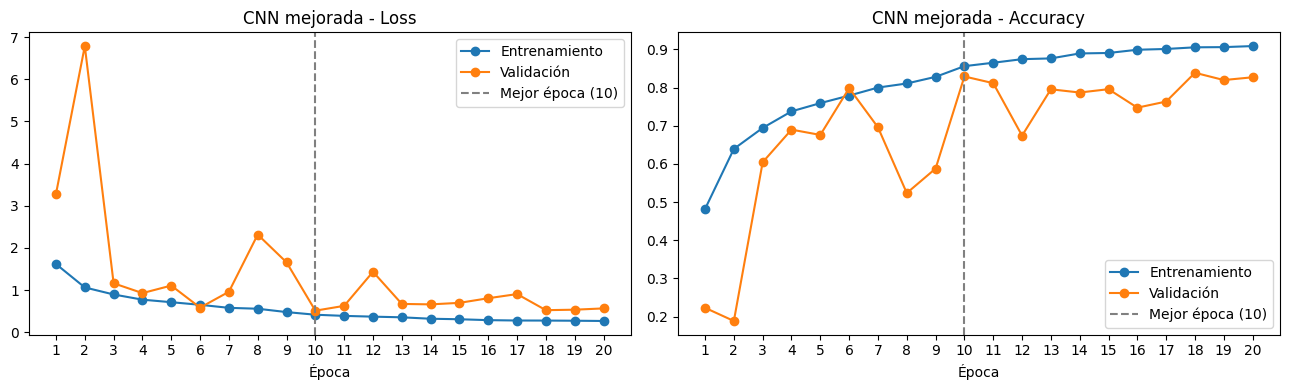

,parametros,epocas,mejor_epoca,train_acc,val_acc,val_loss
CNN base,4289615.0,8.0,4.0,0.935266,0.911569,0.270924
CNN mejorada,112367.0,20.0,10.0,0.856224,0.829194,0.511746


In [ ]:
graficar_historia(hist_mejorado, 'CNN mejorada')

mejor = int(np.argmin(hist_mejorado.history['val_loss']))
resultados['CNN mejorada'] = {
    'parametros': modelo_mejorado.count_params(),
    'epocas': len(hist_mejorado.history['loss']),
    'mejor_epoca': mejor + 1,
    'train_acc': hist_mejorado.history['accuracy'][mejor],
    'val_acc': hist_mejorado.history['val_accuracy'][mejor],
    'val_loss': hist_mejorado.history['val_loss'][mejor],
}
pd.DataFrame(resultados).T

Sin BatchNormalization, el desfase desaparece: en modo predicción, el entrenamiento rinde 93,5%, por encima del 90,8% registrado durante el entrenamiento, que es lo esperado.
Las curvas son estables, y la validación queda por encima del entrenamiento: el augmentation y el dropout hacen que entrenar sea más difícil que validar. No hay sobreajuste.
Con 38 veces menos parámetros, supera al modelo base (93,5% contra 91,2% en validación; val_loss 0,209 contra 0,271).
Precisión importante: esto no significa que BatchNormalization sea perjudicial en general (la mayoría de las redes modernas lo usan). En esta red pequeña, combinado con augmentation y pesos por clase, sus estadísticas de entrenamiento y de predicción quedaron desfasadas.
La mejor época fue la 36 de 40: probablemente el modelo podía mejorar algo más con más épocas.

Celda 6.4: diagnóstico (agrégala debajo de la 6.3)

In [ ]:
# Prueba 1: el modelo en modo predicción con las imágenes de ENTRENAMIENTO
# (evaluate no aplica augmentation ni dropout)
_, acc_train_inf = modelo_mejorado.evaluate(train_ds, verbose=0)
_, acc_val_inf = modelo_mejorado.evaluate(val_ds, verbose=0)
print(f"Entrenamiento (modo predicción): {acc_train_inf:.3f}")
print(f"Validación    (modo predicción): {acc_val_inf:.3f}")

# Prueba 2: ¿el modelo predice demasiado alguna clase?
pred = modelo_mejorado.predict(val_ds, verbose=0).argmax(axis=1)
comparacion = pd.DataFrame({
    'reales': pd.Series(y_val).value_counts().sort_index(),
    'predichas': pd.Series(pred).value_counts().sort_index(),
}).fillna(0).astype(int)
comparacion.index = [CLASES[i] for i in comparacion.index]
comparacion['diferencia'] = comparacion['predichas'] - comparacion['reales']
comparacion.sort_values('diferencia', ascending=False)

Entrenamiento (modo predicción): 0.829
Validación    (modo predicción): 0.829


,reales,predichas,diferencia
Tomato_healthy,255,344,89
Potato___Early_blight,160,229,69
Tomato__Tomato_mosaic_virus,60,102,42
Tomato_Septoria_leaf_spot,283,315,32
Potato___healthy,24,46,22
Potato___Late_blight,160,182,22
Tomato__Target_Spot,225,228,3
Tomato_Early_blight,160,160,0
Pepper__bell___Bacterial_spot,160,157,-3
Tomato_Leaf_Mold,152,148,-4


6.5:Experimento: mismo Modelo 2 pero SIN BatchNormalization

Epoch 1/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.2118 - loss: 2.4072 - val_accuracy: 0.4188 - val_loss: 1.7939 - learning_rate: 0.0010
Epoch 2/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4120 - loss: 1.7769 - val_accuracy: 0.5588 - val_loss: 1.3522 - learning_rate: 0.0010
Epoch 3/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5302 - loss: 1.4089 - val_accuracy: 0.5927 - val_loss: 1.1823 - learning_rate: 0.0010
Epoch 4/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5913 - loss: 1.1892 - val_accuracy: 0.5978 - val_loss: 1.1804 - learning_rate: 0.0010
Epoch 5/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6452 - loss: 1.0506 - val_accuracy: 0.7659 - val_loss: 0.7325 - learning_rate: 0.0010
Epoch 6/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6632 - loss: 0.9697 - val_accuracy: 0.7738 - val_loss: 0.6890 - learning_rate: 0.0010
Epoch 7/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6772 - loss: 0.9306 - 

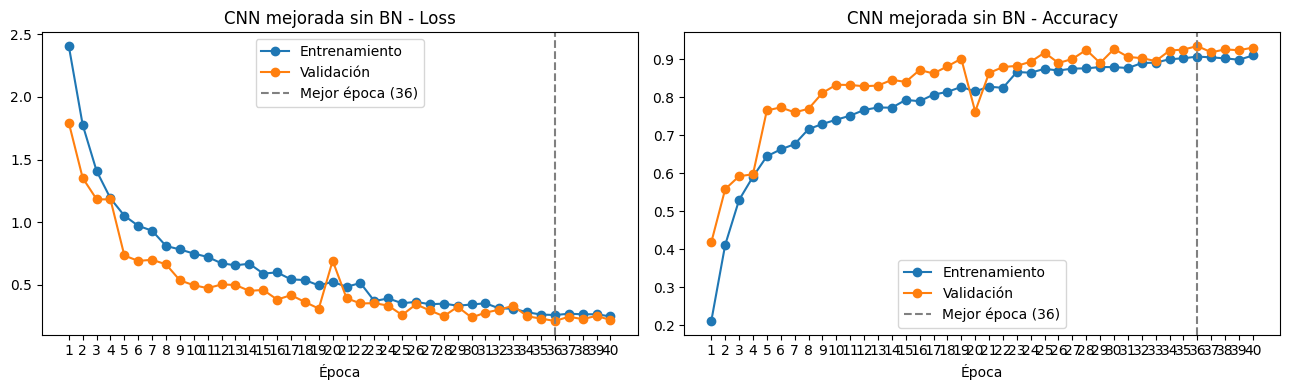

Entrenamiento (modo predicción): 0.935


,parametros,epocas,mejor_epoca,train_acc,val_acc,val_loss
CNN base,4289615.0,8.0,4.0,0.935266,0.911569,0.270924
CNN mejorada,112367.0,20.0,10.0,0.856224,0.829194,0.511746
CNN mejorada sin BN,111695.0,40.0,36.0,0.907556,0.935191,0.208668


In [ ]:
# Experimento: mismo Modelo 2 pero SIN BatchNormalization
def crear_cnn_sin_bn(dropout=0.5):
    entrada = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation(entrada)
    x = layers.Rescaling(1./255)(x)
    for filtros in [32, 64, 128]:                       # mismos filtros
        x = layers.Conv2D(filtros, (3, 3), padding='same', activation='relu')(x)
        x = layers.MaxPooling2D((2, 2))(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    salida = layers.Dense(NUM_CLASES, activation='softmax')(x)
    return keras.Model(entrada, salida, name='CNN_mejorada_sin_BN')

modelo_sin_bn = crear_cnn_sin_bn()
modelo_sin_bn.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks_sin_bn = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

hist_sin_bn = modelo_sin_bn.fit(train_ds, validation_data=val_ds, epochs=40,
                                class_weight=class_weight, callbacks=callbacks_sin_bn)

graficar_historia(hist_sin_bn, 'CNN mejorada sin BN')

# Diagnóstico: ¿desapareció el desfase?
_, acc_train_inf = modelo_sin_bn.evaluate(train_ds, verbose=0)
print(f"Entrenamiento (modo predicción): {acc_train_inf:.3f}")

mejor = int(np.argmin(hist_sin_bn.history['val_loss']))
resultados['CNN mejorada sin BN'] = {
    'parametros': modelo_sin_bn.count_params(),
    'epocas': len(hist_sin_bn.history['loss']),
    'mejor_epoca': mejor + 1,
    'train_acc': hist_sin_bn.history['accuracy'][mejor],
    'val_acc': hist_sin_bn.history['val_accuracy'][mejor],
    'val_loss': hist_sin_bn.history['val_loss'][mejor],
}
pd.DataFrame(resultados).T

7.1: arquitectura

In [ ]:
def bloque_residual(x, filtros):
    atajo = x                                                     # guardamos la entrada (el "atajo")
    y = layers.Conv2D(filtros, (3, 3), padding='same', activation='relu')(x)
    y = layers.Conv2D(filtros, (3, 3), padding='same')(y)        # sin activación: se activa después de sumar
    if atajo.shape[-1] != filtros:
        # Si cambian los canales, una convolución 1x1 ajusta el atajo para poder sumarlo
        atajo = layers.Conv2D(filtros, (1, 1), padding='same')(atajo)
    y = layers.Add()([y, atajo])                                  # F(x) + x  <- la conexión residual
    y = layers.Activation('relu')(y)                              # activación DESPUÉS de sumar (como en el PPT)
    return layers.MaxPooling2D((2, 2))(y)

def crear_resnet(dropout=0.5):
    entrada = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation(entrada)
    x = layers.Rescaling(1./255)(x)
    for filtros in [32, 64, 128]:                                 # mismos filtros que el Modelo 2
        x = bloque_residual(x, filtros)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    salida = layers.Dense(NUM_CLASES, activation='softmax')(x)
    return keras.Model(entrada, salida, name='ResNet_residual')

modelo_resnet = crear_resnet()
modelo_resnet.summary()

Model: "ResNet_residual"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 128, 128,  │          0 │ input_layer_12[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_8         │ (None, 128, 128,  │          0 │ augmentation[4][… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │        896 │ rescaling_8[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_21[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 128, 128,  │        128 │ rescaling_8[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ conv2d_22[0][0],  │
│                     │ 32)               │            │ conv2d_23[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_15       │ (None, 128, 128,  │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_24    │ (None, 64, 64,    │          0 │ activation_15[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_24… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_24[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 64, 64,    │      2,112 │ max_pooling2d_24… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64,    │          0 │ conv2d_25[0][0],  │
│                     │ 64)               │            │ conv2d_26[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_16       │ (None, 64, 64,    │          0 │ add_1[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_25    │ (None, 32, 32,    │          0 │ activation_16[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_25… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_27[0][0] 

 Total params: 316,015 (1.21 MB)

 Trainable params: 316,015 (1.21 MB)

 Non-trainable params: 0 (0.00 B)

ResNet (He et al., 2015) introduce el bloque residual: la entrada del bloque se salta las capas intermedias y se suma a su salida antes de la activación:

salida = ReLU( F(x) + x )

Así, el bloque solo aprende la diferencia (el residuo) respecto de su entrada. Si un bloque no aporta, basta con que F(x) ≈ 0 y la señal pasa intacta. Esto facilita el flujo del gradiente durante el backpropagation y permite entrenar redes muy profundas, evitando la degradación y el desvanecimiento del gradiente (PPT 2.3.2 y guía 2.3.1).

Diseño controlado: se construyó una ResNet con 3 bloques residuales, igual en todo al Modelo 2 sin BatchNorm (mismos filtros 32, 64 y 128; GlobalAveragePooling; Dense 128; dropout 0,5; augmentation; pesos por clase), con la única diferencia de las conexiones residuales. Así, la comparación responde una pregunta concreta: ¿aportan las conexiones residuales?

Cada bloque tiene dos Conv2D de 3×3. La segunda no tiene activación, porque la ReLU se aplica después de la suma, como describe el material del curso.
Cuando cambia el número de canales, el atajo pasa por una convolución 1×1 que lo ajusta para poder sumarlo.
Total: 316.015 parámetros (2,8 veces más que el Modelo 2 sin BN, por la segunda convolución de cada bloque y los atajos 1×1).
La ResNet original usa BatchNormalization; aquí se omitió por coherencia con el estudio de ablación de la sección 6.

Celda 7.2: entrenamiento

In [ ]:
modelo_resnet.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks_resnet = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

hist_resnet = modelo_resnet.fit(train_ds, validation_data=val_ds, epochs=40,
                                class_weight=class_weight, callbacks=callbacks_resnet)

Epoch 1/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1485 - loss: 2.5529 - val_accuracy: 0.2238 - val_loss: 2.2151 - learning_rate: 0.0010
Epoch 2/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.3565 - loss: 2.0227 - val_accuracy: 0.4949 - val_loss: 1.4709 - learning_rate: 0.0010
Epoch 3/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5157 - loss: 1.4469 - val_accuracy: 0.6832 - val_loss: 0.9619 - learning_rate: 0.0010
Epoch 4/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6133 - loss: 1.1564 - val_accuracy: 0.6569 - val_loss: 1.0103 - learning_rate: 0.0010
Epoch 5/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6725 - loss: 0.9885 - val_accuracy: 0.5151 - val_loss: 1.6302 - learning_rate: 0.0010
Epoch 6/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7124 - loss: 0.8546 - val_accuracy: 0.7783 - val_loss: 0.6604 - learning_rate: 0.0010
Epoch 7/40
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7530 - loss: 0.7386 - 

Celda 7.3: curvas, diagnóstico y tabla

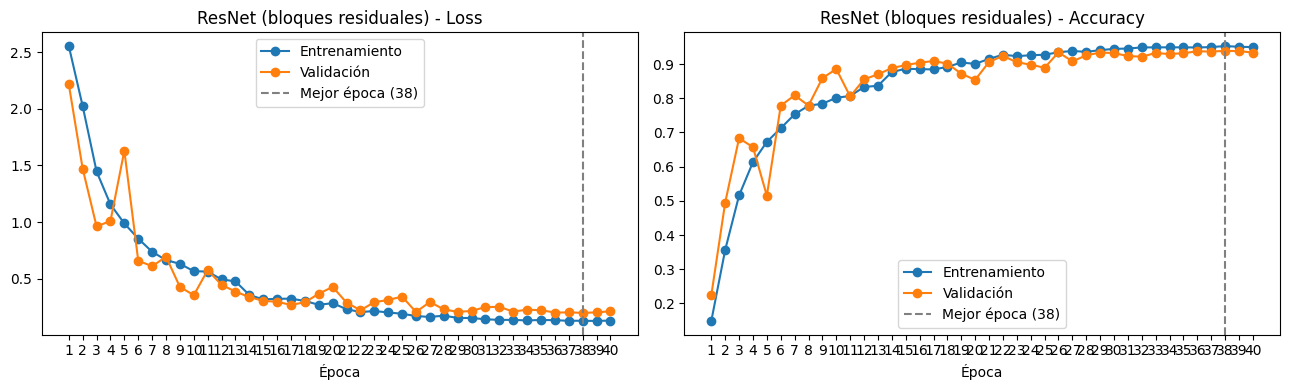

Entrenamiento (modo predicción): 0.942


,parametros,epocas,mejor_epoca,train_acc,val_acc,val_loss
CNN base,4289615.0,8.0,4.0,0.935266,0.911569,0.270924
CNN mejorada,112367.0,20.0,10.0,0.856224,0.829194,0.511746
CNN mejorada sin BN,111695.0,40.0,36.0,0.907556,0.935191,0.208668
ResNet residual,316015.0,40.0,38.0,0.952604,0.938522,0.200048


In [ ]:
graficar_historia(hist_resnet, 'ResNet (bloques residuales)')

_, acc_train_inf = modelo_resnet.evaluate(train_ds, verbose=0)
print(f"Entrenamiento (modo predicción): {acc_train_inf:.3f}")

# Limpiamos filas de los intentos descartados (ResNet50V2 preentrenada)
resultados.pop('ResNet50V2 TL', None)
resultados.pop('ResNet50V2 fine-tuning', None)

mejor = int(np.argmin(hist_resnet.history['val_loss']))
resultados['ResNet residual'] = {
    'parametros': modelo_resnet.count_params(),
    'epocas': len(hist_resnet.history['loss']),
    'mejor_epoca': mejor + 1,
    'train_acc': hist_resnet.history['accuracy'][mejor],
    'val_acc': hist_resnet.history['val_accuracy'][mejor],
    'val_loss': hist_resnet.history['val_loss'][mejor],
}
pd.DataFrame(resultados).T

Mejor época: 38 de 40. Accuracy de 95,3% en entrenamiento y 93,9% en validación (val_loss 0,200).
Las curvas son estables, sin sobreajuste marcado y sin desfase entre entrenamiento y predicción (94,2% en modo predicción).
Frente al Modelo 2 sin BN, la mejora es de apenas 0,3 puntos en accuracy de validación, con 2,8 veces más parámetros. Esa diferencia no es concluyente: con otra semilla podría invertirse.
Interpretación: es coherente con el material del curso, que indica que la ventaja de ResNet aparece especialmente en redes profundas. Esta red tiene solo 6 capas convolucionales; a esa profundidad, el desvanecimiento del gradiente casi no se presenta, por lo que las conexiones residuales tienen poco que resolver.

8. Ajuste de hiperparámetros
8.0: funciones del experimento

In [ ]:
import time

def experimento(lr=1e-3, batch=32, dropout=0.5, epocas=20):
    keras.utils.set_random_seed(SEED)          # misma semilla en cada prueba: comparación justa
    # Dataset con el tamaño de batch indicado
    tr = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train), seed=SEED) \
           .map(cargar_imagen, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)
    va = tf.data.Dataset.from_tensor_slices((X_val, y_val)) \
           .map(cargar_imagen, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)
    modelo = crear_resnet(dropout=dropout)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    inicio = time.time()
    hist = modelo.fit(tr, validation_data=va, epochs=epocas,
                      class_weight=class_weight, verbose=0)   # verbose=0: sin log largo
    minutos = (time.time() - inicio) / 60
    h = hist.history
    print(f"lr={lr} | batch={batch} | dropout={dropout} -> "
          f"mejor val_acc={max(h['val_accuracy']):.3f} | menor val_loss={min(h['val_loss']):.3f} | {minutos:.1f} min")
    return hist, minutos

def graficar_comparacion(historias, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for nombre, (hist, _) in historias.items():
        ep = range(1, len(hist.history['loss']) + 1)
        ax[0].plot(ep, hist.history['val_loss'], marker='o', markersize=3, label=nombre)
        ax[1].plot(ep, hist.history['val_accuracy'], marker='o', markersize=3, label=nombre)
    ax[0].set_title(f'{titulo} - val_loss'); ax[1].set_title(f'{titulo} - val_accuracy')
    for a in ax: a.set_xlabel('Época'); a.legend()
    plt.tight_layout(); plt.show()

def tabla_comparacion(historias):
    filas = {}
    for nombre, (hist, minutos) in historias.items():
        h = hist.history
        filas[nombre] = {'mejor_val_acc': max(h['val_accuracy']),
                         'menor_val_loss': min(h['val_loss']),
                         'brecha_final (train - val acc)': h['accuracy'][-1] - h['val_accuracy'][-1],
                         'minutos': minutos}
    return pd.DataFrame(filas).T.round(3)

# Configuración base: se entrena una sola vez y se reutiliza en los 3 estudios
base = experimento()

lr=0.001 | batch=32 | dropout=0.5 -> mejor val_acc=0.919 | menor val_loss=0.252 | 1.0 min


Celda 8.1: learning rate

lr=0.01 | batch=32 | dropout=0.5 -> mejor val_acc=0.155 | menor val_loss=2.690 | 1.0 min
lr=0.0001 | batch=32 | dropout=0.5 -> mejor val_acc=0.836 | menor val_loss=0.525 | 1.0 min


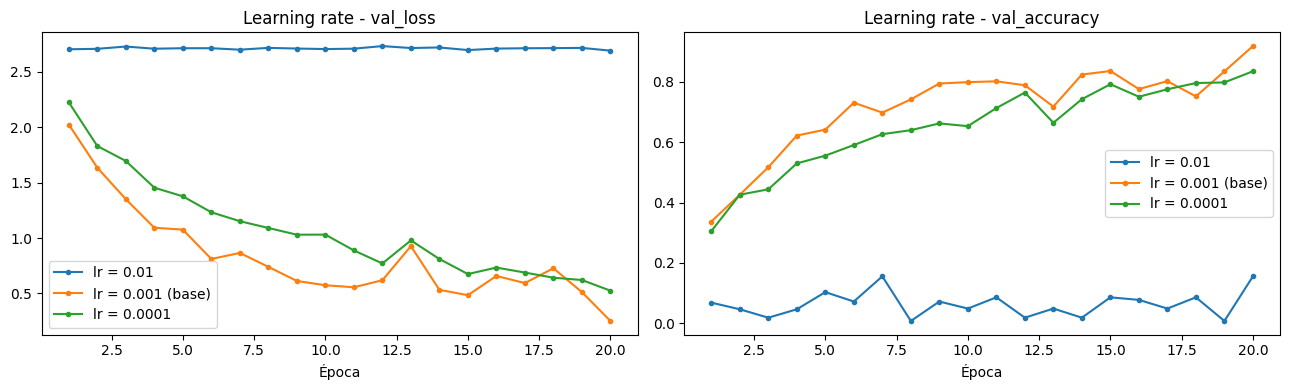

,mejor_val_acc,menor_val_loss,brecha_final (train - val acc),minutos
lr = 0.01,0.155,2.690,-0.107,0.981
lr = 0.001 (base),0.919,0.252,-0.070,0.981
lr = 0.0001,0.836,0.525,-0.101,0.985


In [ ]:
exp_lr = {'lr = 0.01': experimento(lr=1e-2),
          'lr = 0.001 (base)': base,
          'lr = 0.0001': experimento(lr=1e-4)}
graficar_comparacion(exp_lr, 'Learning rate')
tabla_comparacion(exp_lr)

Se estudia el efecto de tres hiperparámetros sobre la ResNet residual, cambiando uno a la vez y dejando el resto fijo en la configuración base (lr 0,001; batch 32; dropout 0,5).

Todos los experimentos entrenan 20 épocas fijas, sin EarlyStopping, para que tengan el mismo presupuesto y las curvas se comparen época a época.
Se quita ReduceLROnPlateau, porque modificaría el learning rate durante el entrenamiento y contaminaría la comparación.
Se fija la misma semilla en cada experimento.

Por tener menos épocas y learning rate fijo, la configuración base llega a 91,9% (frente al 93,9% de la sección 7). Lo relevante aquí es la comparación entre experimentos, no el valor absoluto.
lr = 0,01: el modelo no aprendió. El val_loss se mantiene plano en ~2,69 durante las 20 épocas, prácticamente igual a ln(15) ≈ 2,71, que es la pérdida de un modelo que asigna la misma probabilidad a las 15 clases (adivina al azar). El accuracy oscila en torno al 6,7% (1 de 15). El paso es tan grande que los pesos saltan a valores extremos en las primeras actualizaciones, y muchas neuronas ReLU quedan con salida 0 de forma permanente (neuronas muertas), sin recibir gradiente.
lr = 0,001: aprende rápido y obtiene el menor val_loss durante casi todo el entrenamiento.


Celda 8.2: tamaño de batch

lr=0.001 | batch=64 | dropout=0.5 -> mejor val_acc=0.908 | menor val_loss=0.284 | 0.9 min
lr=0.001 | batch=128 | dropout=0.5 -> mejor val_acc=0.840 | menor val_loss=0.466 | 0.9 min


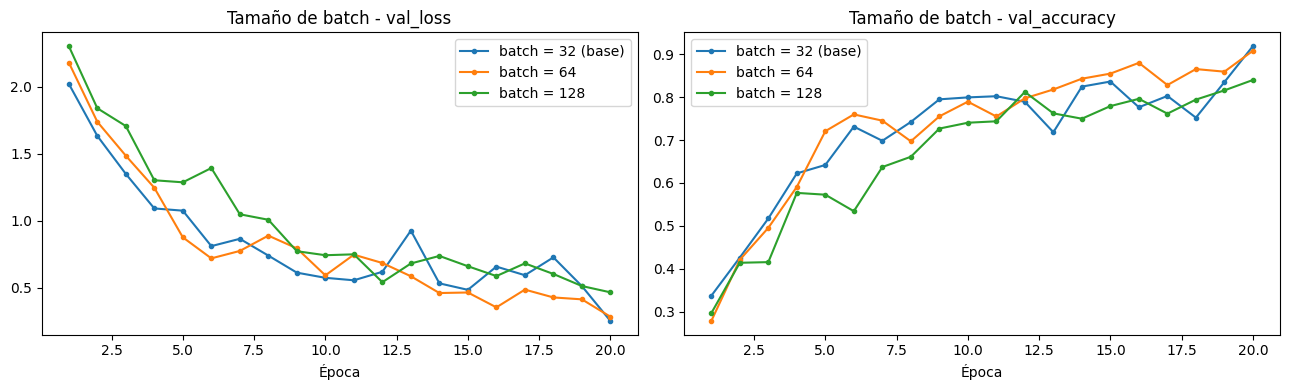

,mejor_val_acc,menor_val_loss,brecha_final (train - val acc),minutos
batch = 32 (base),0.919,0.252,-0.070,0.981
batch = 64,0.908,0.284,-0.042,0.898
batch = 128,0.840,0.466,-0.017,0.863


In [ ]:
exp_batch = {'batch = 32 (base)': base,
             'batch = 64': experimento(batch=64),
             'batch = 128': experimento(batch=128)}
graficar_comparacion(exp_batch, 'Tamaño de batch')
tabla_comparacion(exp_batch)

El modelo actualiza sus pesos una vez por lote. Con batch 128 hace 4 veces menos actualizaciones que con batch 32 en el mismo número de épocas, por lo que con el mismo learning rate avanza menos: llega a 84% con la curva aún subiendo. No aprende peor, sino que necesita más épocas (o un learning rate mayor).
Batch 32 y 64 rinden prácticamente igual: el 91,9% de la base corresponde a un salto en la última época, y entre las épocas 14 y 19 el batch 64 va levemente por encima, con una curva más suave (promedia el gradiente sobre más imágenes).
El tiempo de entrenamiento casi no cambió (0,98 contra 0,86 minutos): el cuello de botella probablemente es la lectura y decodificación de imágenes, no la GPU.
La brecha se reduce al aumentar el batch: los lotes pequeños agregan "ruido" al gradiente, que actúa como una regularización leve.
El PPT 2.3.2 usa batch 128 con CIFAR-10. Este experimento muestra que, con igual número de épocas, un batch grande necesita compensar las actualizaciones que pierde.

Celda 8.3: dropout

lr=0.001 | batch=32 | dropout=0.0 -> mejor val_acc=0.913 | menor val_loss=0.256 | 1.0 min
lr=0.001 | batch=32 | dropout=0.3 -> mejor val_acc=0.891 | menor val_loss=0.317 | 1.0 min


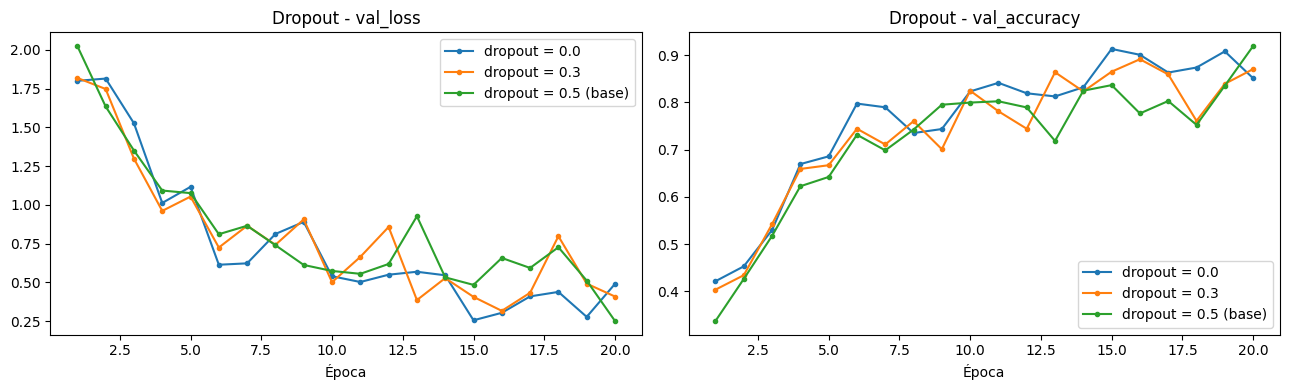

,mejor_val_acc,menor_val_loss,brecha_final (train - val acc),minutos
dropout = 0.0,0.913,0.256,0.073,0.980
dropout = 0.3,0.891,0.317,0.026,0.991
dropout = 0.5 (base),0.919,0.252,-0.070,0.981


In [ ]:
exp_drop = {'dropout = 0.0': experimento(dropout=0.0),
            'dropout = 0.3': experimento(dropout=0.3),
            'dropout = 0.5 (base)': base}
graficar_comparacion(exp_drop, 'Dropout')
tabla_comparacion(exp_drop)

En accuracy los tres valores son equivalentes: las curvas se cruzan constantemente y las diferencias están dentro del ruido.
La brecha sí cambia de forma ordenada: sin dropout, el entrenamiento ya supera a la validación (señal temprana de sobreajuste). Al aumentar el dropout la brecha se cierra, y con 0,5 se invierte. Es el efecto esperado del dropout: impedir que el modelo memorice.
El accuracy no cambia porque el data augmentation ya regulariza bastante y en 20 épocas no alcanza a aparecer un sobreajuste fuerte. En entrenamientos más largos, lo esperable es que la brecha sin dropout siga creciendo.

sección 9: comparación de arquitecturas
Celda 9.1: métricas por modelo en validación

In [ ]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

modelos = {
    'CNN base': modelo_base,
    'CNN mejorada': modelo_mejorado,
    'CNN mejorada sin BN': modelo_sin_bn,
    'ResNet residual': modelo_resnet,
}

idx_papa = CLASES.index('Potato___healthy')
idx_mosaico = CLASES.index('Tomato__Tomato_mosaic_virus')

filas = {}
for nombre, m in modelos.items():
    pred = m.predict(val_ds, verbose=0).argmax(axis=1)   # val_ds no está mezclado: el orden calza con y_val
    prec, rec, f1, _ = precision_recall_fscore_support(y_val, pred, average='macro', zero_division=0)
    f1_clases = precision_recall_fscore_support(y_val, pred, average=None, zero_division=0)[2]
    filas[nombre] = {
        'parametros': m.count_params(),
        'accuracy': accuracy_score(y_val, pred),
        'precision_macro': prec,
        'recall_macro': rec,
        'F1_macro': f1,
        'F1 Potato healthy': f1_clases[idx_papa],
        'F1 Mosaic virus': f1_clases[idx_mosaico],
        'peor F1': f1_clases.min(),
        'clase con peor F1': CLASES[f1_clases.argmin()],
    }

tabla_val = pd.DataFrame(filas).T
tabla_val

,parametros,accuracy,precision_macro,recall_macro,F1_macro,F1 Potato healthy,F1 Mosaic virus,peor F1,clase con peor F1
CNN base,4289615,0.911569,0.900489,0.890563,0.893276,0.790698,0.920635,0.753521,Tomato_Early_blight
CNN mejorada,112367,0.829194,0.793124,0.849656,0.80634,0.657143,0.728395,0.639511,Tomato_Spider_mites_Two_spotted_spider_mite
CNN mejorada sin BN,111695,0.935191,0.924776,0.937369,0.929232,0.875,0.952381,0.864553,Tomato_Early_blight
ResNet residual,316015,0.938522,0.930236,0.933785,0.929587,0.863636,0.952381,0.857923,Pepper__bell___Bacterial_spot


Criterio de selección, definido antes de ver los resultados:

Métrica principal: F1 macro en validación, que promedia el F1 de las 15 clases dándole el mismo peso a cada una, sin importar su tamaño. Con un desbalance de 21 veces, es más representativa que el accuracy.
Si dos modelos difieren en menos de 0,5 puntos se consideran empatados, y se elige el más simple (menos parámetros).
El conjunto de test no participa en la decisión.

Celda 9.2: curvas comparadas de los 4 modelos

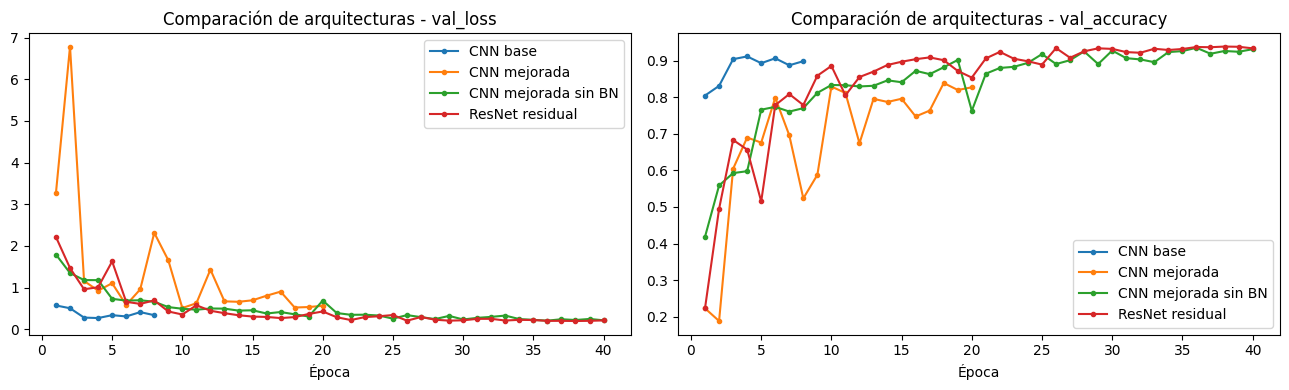

In [ ]:
historias_modelos = {
    'CNN base': (hist_base, 0),
    'CNN mejorada': (hist_mejorado, 0),
    'CNN mejorada sin BN': (hist_sin_bn, 0),
    'ResNet residual': (hist_resnet, 0),
}
graficar_comparacion(historias_modelos, 'Comparación de arquitecturas')

CNN base: aprende muy rápido (91% en la época 4), pero se detiene en la época 8 por sobreajuste.
CNN mejorada con BN: validación inestable, con saltos bruscos durante las primeras 12 épocas, causados por el desfase de BatchNormalization.
CNN sin BN y ResNet residual: aprenden más lento por la regularización, pero de forma estable. Desde la época 25 sus curvas prácticamente se superponen, y terminan en el mismo nivel (~93,5–94%), por encima del modelo base.

10. Evaluación final en el conjunto de test
Celda 10.1: métricas en test

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

modelo_final = modelo_sin_bn

# Nombres cortos para que las tablas y la matriz se lean bien
def nombre_corto(c):
    for largo, corto in [('Pepper__bell___', 'Pimentón '), ('Potato___', 'Papa '),
                         ('Tomato__Tomato_', 'Tomate '), ('Tomato__', 'Tomate '), ('Tomato_', 'Tomate ')]:
        c = c.replace(largo, corto)
    return c.replace('_', ' ')
nombres = [nombre_corto(c) for c in CLASES]

test_loss, test_acc = modelo_final.evaluate(test_ds, verbose=0)
print(f"Test -> loss: {test_loss:.4f} | accuracy: {test_acc:.4f}\n")

probs = modelo_final.predict(test_ds, verbose=0)    # test_ds no está mezclado: el orden calza con y_test
y_pred = probs.argmax(axis=1)
print(classification_report(y_test, y_pred, target_names=nombres, digits=3))

Test -> loss: 0.2090 | accuracy: 0.9336

                                             precision    recall  f1-score   support

                    Pimentón Bacterial spot      0.863     0.950     0.904       199
                           Pimentón healthy      0.934     0.997     0.964       296
                          Papa Early blight      0.921     0.990     0.954       200
                           Papa Late blight      0.955     0.845     0.897       200
                               Papa healthy      0.962     0.833     0.893        30
                      Tomate Bacterial spot      0.988     0.930     0.958       426
                        Tomate Early blight      0.737     0.940     0.826       200
                         Tomate Late blight      0.966     0.825     0.890       382
                           Tomate Leaf Mold      0.922     0.937     0.930       190
                  Tomate Septoria leaf spot      0.942     0.879     0.909       354
Tomate Spider mites Two

Modelo evaluado: CNN mejorada sin BN. El test se utilizó una sola vez.

Test: accuracy 93,4%, loss 0,209. En validación fue 93,5% y 0,209: prácticamente idénticos. El modelo generaliza a imágenes nuevas y no hubo fuga de datos durante la selección.
Promedios: precision macro 0,927, recall macro 0,928, F1 macro 0,925, F1 ponderado 0,934.

Lectura por clase:

Mejores: Tomate healthy (F1 0,989), Tomate YellowLeaf Curl Virus (0,974) y Pimentón healthy (0,964).
Tomate Early blight, el peor F1 (0,826): recall alto (0,940), pero precision baja (0,737). Casi no se le escapa ninguna, pero el modelo etiqueta como Early blight imágenes de otras clases: es la clase hacia la que "tira" cuando duda.
Los dos Late blight tienen el recall más bajo: Tomate 0,825 y Papa 0,845. Se le escapa ~16% de estos casos.
Papa healthy: recall 0,833 con solo 30 imágenes de test (5 errores). Cada imagen pesa 3,3 puntos, por lo que esta métrica es poco estable.
Tomate mosaic virus: F1 de 0,942 con solo 75 imágenes. Aquí se ve el efecto positivo de los pesos por clase.


Celda 10.2: matriz de confusión

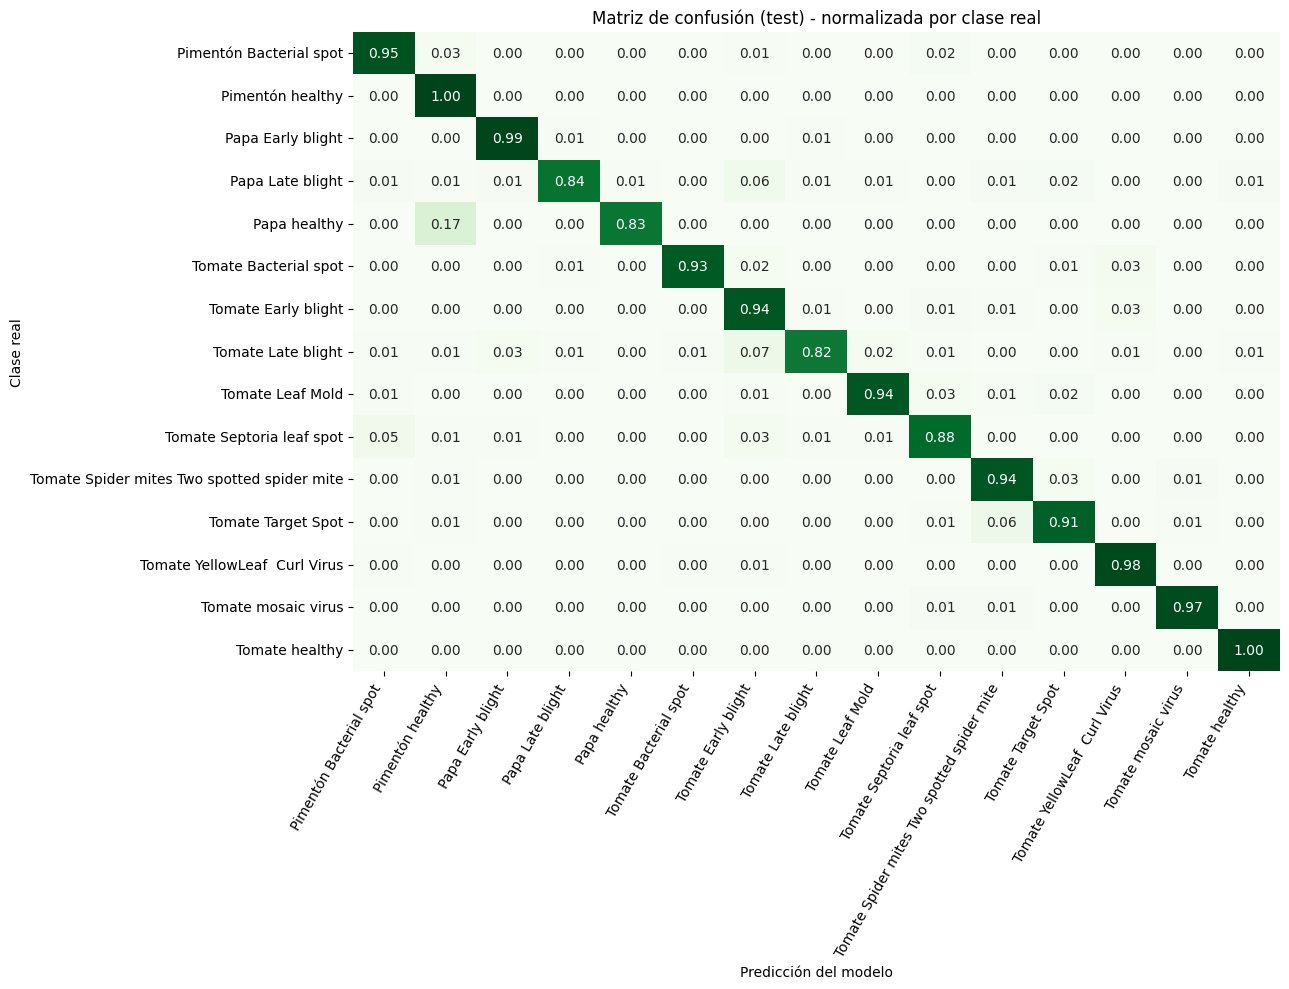

,Clase real,Predicha como,Imágenes
0,Tomate Late blight,Tomate Early blight,28
1,Tomate Septoria leaf spot,Pimentón Bacterial spot,18
2,Tomate Target Spot,Tomate Spider mites Two spotted spider mite,18
3,Tomate Bacterial spot,Tomate YellowLeaf Curl Virus,12
4,Papa Late blight,Tomate Early blight,11
5,Tomate Septoria leaf spot,Tomate Early blight,11
6,Tomate Bacterial spot,Tomate Early blight,10
7,Tomate Late blight,Papa Early blight,10


In [ ]:
# Normalizada por fila: cada fila suma 1, la diagonal es el recall de cada clase
cm = confusion_matrix(y_test, y_pred, normalize='true')
plt.figure(figsize=(13, 10))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=nombres, yticklabels=nombres, cbar=False)
plt.title('Matriz de confusión (test) - normalizada por clase real')
plt.xlabel('Predicción del modelo'); plt.ylabel('Clase real')
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()

# Las confusiones más frecuentes, en cantidad de imágenes
cm_abs = confusion_matrix(y_test, y_pred)
pares = [(nombres[i], nombres[j], cm_abs[i, j])
         for i in range(len(CLASES)) for j in range(len(CLASES)) if i != j and cm_abs[i, j] > 0]
pd.DataFrame(sorted(pares, key=lambda p: -p[2])[:8], columns=['Clase real', 'Predicha como', 'Imágenes'])

Early blight contra Late blight es la confusión principal: suma 49 imágenes entre las dos especies. Ambas enfermedades producen lesiones marrones en la hoja. Esto explica el recall bajo de los Late blight y la precision baja de Tomate Early blight.
El modelo confunde entre especies: Septoria (tomate) → Bacterial spot (pimentón), Papa Late blight → Tomate Early blight. Aprendió a reconocer el tipo de lesión, pero no le da suficiente peso a la forma de la hoja, que es la que indica la especie.
Tal como se anticipó en el análisis exploratorio, las clases con síntomas visualmente similares concentran los errores.

Celda 10.3: imágenes mal clasificadas

Imágenes mal clasificadas: 274 de 4128


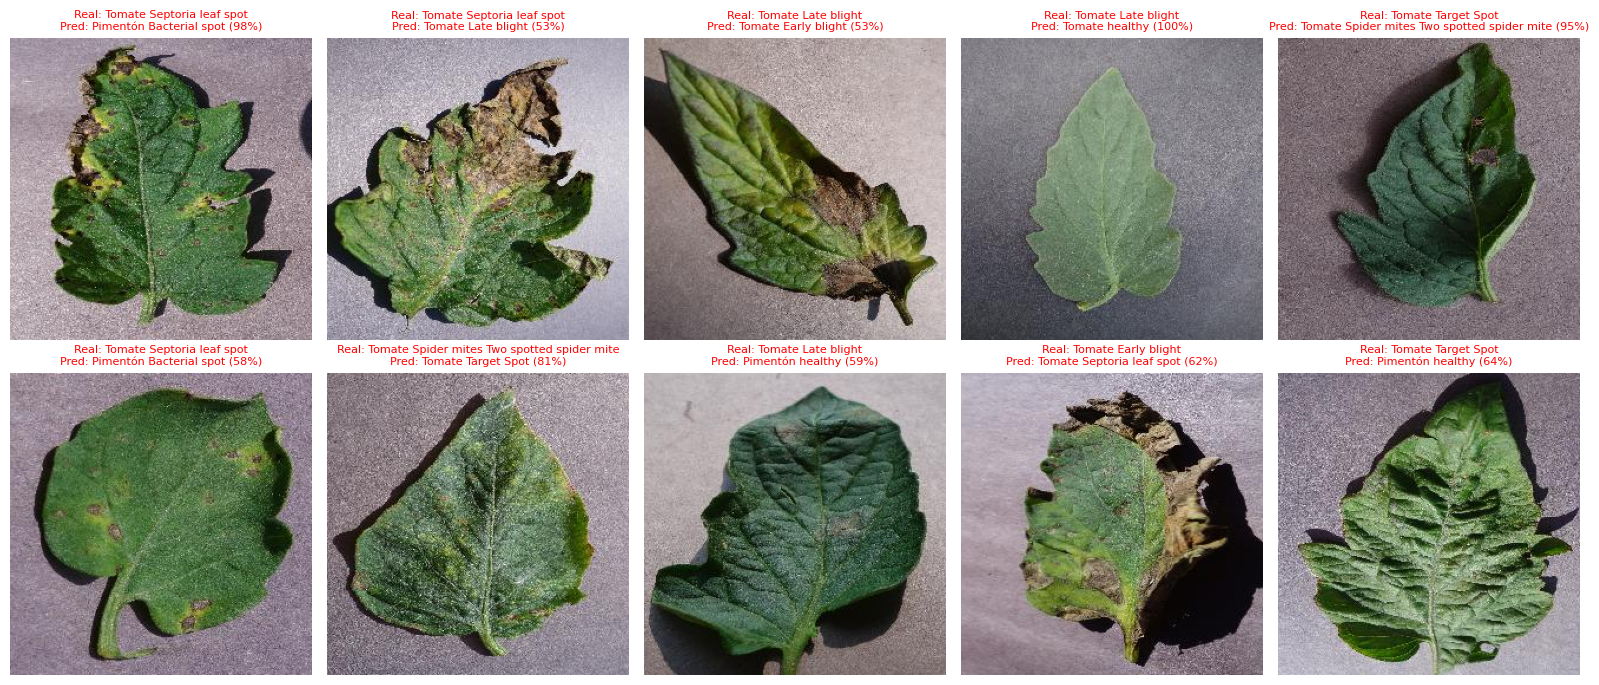

In [ ]:
errores = np.where(y_pred != y_test)[0]
print(f"Imágenes mal clasificadas: {len(errores)} de {len(y_test)}")

plt.figure(figsize=(16, 7))
for k, i in enumerate(errores[:10]):
    plt.subplot(2, 5, k + 1)
    plt.imshow(plt.imread(X_test[i]))
    plt.title(f"Real: {nombres[y_test[i]]}\nPred: {nombres[y_pred[i]]} ({probs[i].max():.0%})",
              fontsize=8, color='red')
    plt.axis('off')
plt.tight_layout(); plt.show()

El modelo se equivoca en 274 de 4.128 imágenes (6,6%).
Se distinguen dos tipos de error según la confianza del modelo en su predicción equivocada:
Errores con confianza alta (por ejemplo, Septoria predicha como Pimentón Bacterial spot con 98%): son los más preocupantes, porque el modelo está "seguro" y un usuario confiaría en esa respuesta.
Errores con confianza baja (por ejemplo, Late blight predicha como Early blight con 53%): el modelo dudaba entre dos clases. En una aplicación real se podrían filtrar con una regla del tipo "si la confianza es menor a 70%, derivar a revisión de un experto".

In [ ]:
modelo_final.save('/content/modelo_final_cnn_sin_bn.keras')

Celda 11 – Justificación del modelo final

Se elige la CNN mejorada sin BatchNormalization:

Criterio principal (definido de antemano): en validación empata con la ResNet residual en F1 macro (0,929 contra 0,930; diferencia de 0,04 puntos, bajo el umbral de 0,5). En caso de empate se elige el modelo más simple: tiene 111.695 parámetros, 2,8 veces menos que la ResNet (316.015) y 38 veces menos que la CNN base (4.289.615).
Es más pareja entre clases: menor diferencia entre accuracy y F1 macro, mejor F1 en la clase minoritaria Potato healthy (0,875 contra 0,864) y un peor F1 por clase más alto (0,865 contra 0,858).
Supera claramente al modelo base (F1 macro 0,929 contra 0,893), sin sobreajuste y con curvas estables.
Se confirma en test: 93,4% de accuracy y F1 macro de 0,925, prácticamente iguales a validación.
Ventaja práctica: pesa ~440 KB (contra 16 MB del modelo base), por lo que podría ejecutarse en un celular en terreno, donde un agricultor tomaría la foto de la hoja.
El modelo final clasifica correctamente el 93,4% de las hojas de test entre 15 clases (F1 macro 0,925), con un modelo liviano de ~112 mil parámetros. Distingue con gran precisión entre hojas sanas y enfermas, y la mayoría de las enfermedades superan un F1 de 0,90. Para el problema planteado, esto permitiría una primera detección automática a partir de una foto, apoyando la detección temprana y reduciendo la dependencia de la inspección visual de un especialista.

El proceso también deja aprendizajes metodológicos: la regularización (GlobalAveragePooling, dropout, augmentation) superó al modelo base con 38 veces menos parámetros; los pesos por clase mejoraron el desempeño en las clases minoritarias; y el diagnóstico en modo predicción permitió detectar y corregir el desfase de BatchNormalization.